In [1]:

%matplotlib inline

import polars as pl
import matplotlib.pyplot as plt

# Make the graphs a bit prettier, and bigger
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['font.family'] = 'sans-serif'


Okay! We're going back to our bike path dataset here. I live in Montreal, and I was curious about whether we're more of a commuter city or a biking-for-fun city -- do people bike more on weekends, or on weekdays?

# 4.1 Adding a 'weekday' column to our dataframe

First, we need to load up the data. We've done this before.

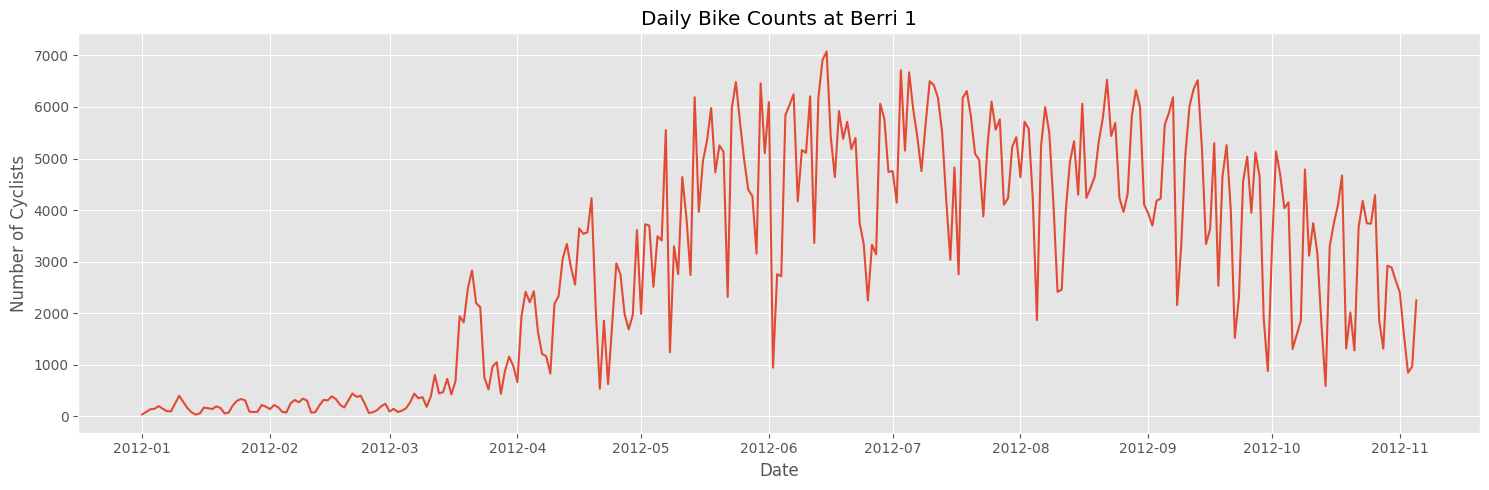

In [2]:
# Read the bike data with Polars
bikes = pl.read_csv(
    "./data/bikes.csv",
    separator=";",
    encoding="windows-1252"
)

# Convert Date to a date type
bikes = bikes.with_columns(
    pl.col("Date").str.to_date(format="%d/%m/%Y")
)

# Plot the daily number of cyclists at Berri 1
plt.figure(figsize=(15, 5))
plt.plot(
    bikes["Date"].to_list(),
    bikes["Berri 1"].to_list()
)
plt.title("Daily Bike Counts at Berri 1")
plt.xlabel("Date")
plt.ylabel("Number of Cyclists")
plt.tight_layout()
plt.show()

Next up, we're just going to look at the Berri bike path. Berri is a street in Montreal, with a pretty important bike path. I use it mostly on my way to the library now, but I used to take it to work sometimes when I worked in Old Montreal. 

So we're going to create a dataframe with just the Berri bikepath in it

In [3]:
# Select the Berri 1 column
berri_bikes = bikes.select("Date", "Berri 1")

In [4]:
berri_bikes.head()

Date,Berri 1
date,i64
2012-01-01,35
2012-01-02,83
2012-01-03,135
2012-01-04,144
2012-01-05,197


Next, we need to add a 'weekday' column. Firstly, we can get the weekday from the index. We haven't talked about indexes yet, but the index is what's on the left on the above dataframe, under 'Date'. It's basically all the days of the year.

In [5]:
# Inspect the Date column
berri_bikes.select("Date").head()

Date
date
2012-01-01
2012-01-02
2012-01-03
2012-01-04
2012-01-05


You can see that actually some of the days are missing -- only 310 days of the year are actually there. Who knows why.

Pandas has a bunch of really great time series functionality, so if we wanted to get the day of the month for each row, we could do it like this:

In [6]:
# Extract the day of the month
berri_bikes.select(
    pl.col("Date").dt.day().alias("day")
).head()

day
i8
1
2
3
4
5


We actually want the weekday, though:

In [7]:
# Extract the weekday
# In Polars, Monday = 1 and Sunday = 7
berri_bikes.select(
    pl.col("Date").dt.weekday().alias("weekday")
).head()

weekday
i8
7
1
2
3
4


These are the days of the week, where 0 is Monday. I found out that 0 was Monday by checking on a calendar.

Now that we know how to *get* the weekday, we can add it as a column in our dataframe like this:

In [8]:
# Add the weekday column
berri_bikes = berri_bikes.with_columns(
    pl.col("Date").dt.weekday().alias("weekday")
)

berri_bikes.head()

# Display the first five rows
berri_bikes.head()

Date,Berri 1,weekday
date,i64,i8
2012-01-01,35,7
2012-01-02,83,1
2012-01-03,135,2
2012-01-04,144,3
2012-01-05,197,4


# 4.2 Adding up the cyclists by weekday

This turns out to be really easy!

Polars DataFrames provide a `group_by()` method that is similar to SQL GROUP BY. It groups rows based on the values in one or more columns, allowing us to aggregate data within each group.

For more details, see the [Polars documentation on grouping and aggregation](https://docs.pola.rs/user-guide/expressions/aggregation/).

In this case, `berri_bikes.group_by("weekday").agg(pl.col("Berri 1").sum())` means: group the rows by weekday and then add up the number of cyclists for each weekday.

In [9]:
# Count the number of cyclists for each weekday
weekday_counts = (
    berri_bikes
    .group_by("weekday")
    .agg(
        pl.col("Berri 1").sum().alias("Berri 1")
    )
    .sort("weekday")
)

weekday_counts

weekday,Berri 1
i8,i64
1,134298
2,135305
3,152972
4,160131
5,141771
6,101578
7,99310


It's hard to remember what 0, 1, 2, 3, 4, 5, 6 mean, so we can fix it up and graph it:

In [10]:
# Replace weekday numbers with weekday names
weekday_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

weekday_counts = weekday_counts.with_columns(
    pl.col("weekday")
    .replace_strict(weekday_names)
    .alias("weekday")
)

weekday_counts

weekday,Berri 1
str,i64
"""Monday""",134298
"""Tuesday""",135305
"""Wednesday""",152972
"""Thursday""",160131
"""Friday""",141771
"""Saturday""",101578
"""Sunday""",99310


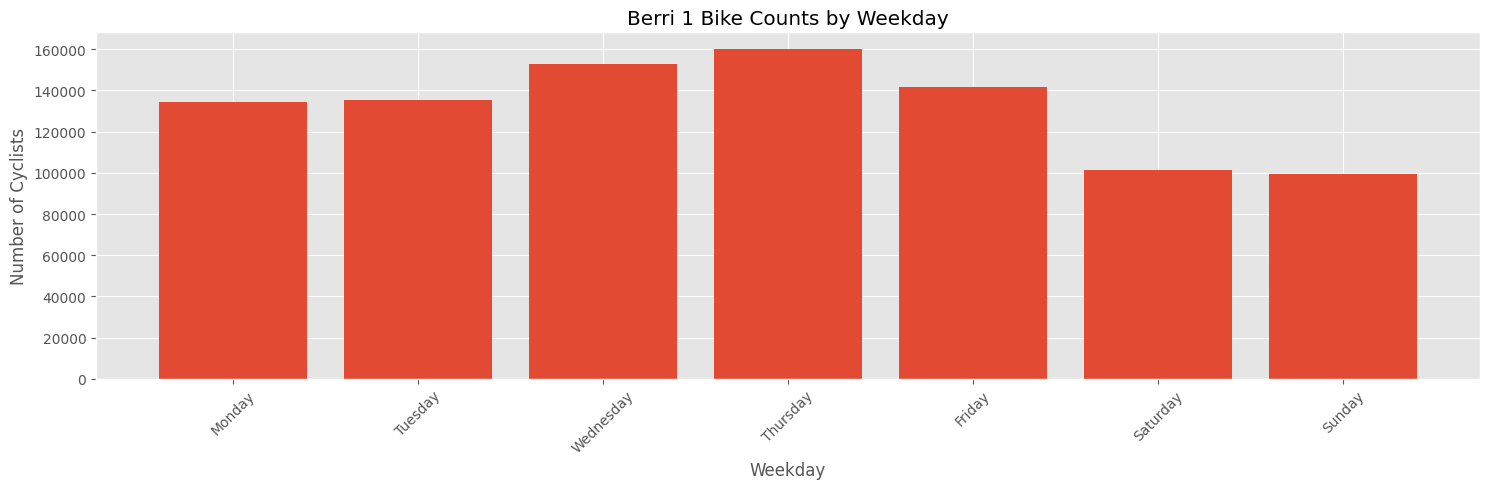

In [11]:
# Plot the number of cyclists for each weekday
plt.figure(figsize=(15, 5))

plt.bar(
    weekday_counts["weekday"].to_list(),
    weekday_counts["Berri 1"].to_list()
)

plt.title("Berri 1 Bike Counts by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Cyclists")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

So it looks like Montrealers are commuter cyclists -- they bike much more during the week. Neat!

# 4.3 Putting it together

Let's put all that together, to prove how easy it is. 6 lines of magical pandas!

If you want to play around, try changing `sum` to `max`, `numpy.median`, or any other function you like.

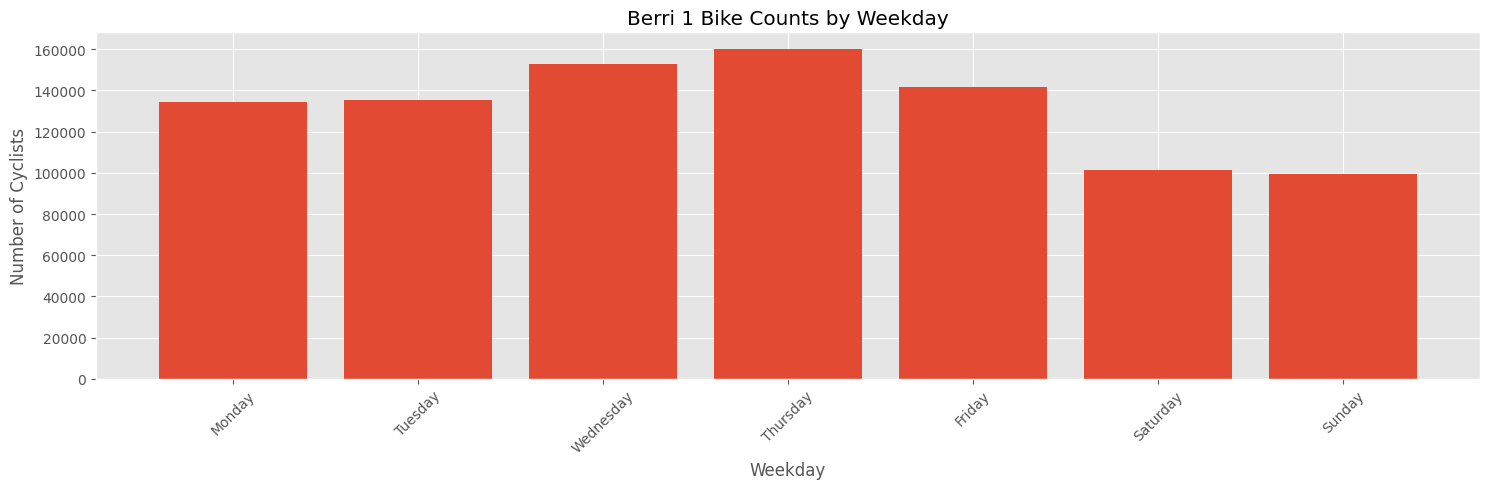

In [12]:

# Read the bike data with Polars
bikes = pl.read_csv(
    "./data/bikes.csv",
    separator=";",
    encoding="windows-1252"
).with_columns(
    pl.col("Date").str.to_date(format="%d/%m/%Y")
)

# Add the weekday column
berri_bikes = bikes.select("Date", "Berri 1").with_columns(
    pl.col("Date").dt.weekday().alias("weekday")
)

# Add up the number of cyclists by weekday
weekday_counts = (
    berri_bikes
    .group_by("weekday")
    .agg(pl.col("Berri 1").sum().alias("Berri 1"))
    .sort("weekday")
)

# Replace weekday numbers with weekday names
weekday_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

weekday_counts = weekday_counts.with_columns(
    pl.col("weekday").replace_strict(weekday_names).alias("weekday")
)

# Plot the results
plt.figure(figsize=(15, 5))
plt.bar(
    weekday_counts["weekday"].to_list(),
    weekday_counts["Berri 1"].to_list()
)
plt.title("Berri 1 Bike Counts by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Cyclists")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
